<a href="https://colab.research.google.com/github/gautamtoni/ScholarRAG/blob/main/heart_disease_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install pandas numpy matplotlib seaborn scikit-learn joblib

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    precision_recall_curve
)

In [3]:
df = pd.read_csv("heart_2020_cleaned.csv")

print("Dataset Shape:", df.shape)

df.head()

Dataset Shape: (319795, 18)


,HeartDisease,BMI,Smoking,AlcoholDrinking,Stroke,PhysicalHealth,MentalHealth,DiffWalking,Sex,AgeCategory,Race,Diabetic,PhysicalActivity,GenHealth,SleepTime,Asthma,KidneyDisease,SkinCancer
0,No,16.60,Yes,No,No,3.0,30.0,No,Female,55-59,White,Yes,Yes,Very good,5.0,Yes,No,Yes
1,No,20.34,No,No,Yes,0.0,0.0,No,Female,80 or older,White,No,Yes,Very good,7.0,No,No,No
2,No,26.58,Yes,No,No,20.0,30.0,No,Male,65-69,White,Yes,Yes,Fair,8.0,Yes,No,No
3,No,24.21,No,No,No,0.0,0.0,No,Female,75-79,White,No,No,Good,6.0,No,No,Yes
4,No,23.71,No,No,No,28.0,0.0,Yes,Female,40-44,White,No,Yes,Very good,8.0,No,No,No


In [4]:
print(df.info())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nTarget Distribution:")
print(df["HeartDisease"].value_counts())

print("\nTarget Percentage:")
print(df["HeartDisease"].value_counts(normalize=True) * 100)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 319795 entries, 0 to 319794
Data columns (total 18 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   HeartDisease      319795 non-null  object 
 1   BMI               319795 non-null  float64
 2   Smoking           319795 non-null  object 
 3   AlcoholDrinking   319795 non-null  object 
 4   Stroke            319795 non-null  object 
 5   PhysicalHealth    319795 non-null  float64
 6   MentalHealth      319795 non-null  float64
 7   DiffWalking       319795 non-null  object 
 8   Sex               319795 non-null  object 
 9   AgeCategory       319795 non-null  object 
 10  Race              319795 non-null  object 
 11  Diabetic          319795 non-null  object 
 12  PhysicalActivity  319795 non-null  object 
 13  GenHealth         319795 non-null  object 
 14  SleepTime         319795 non-null  float64
 15  Asthma            319795 non-null  object 
 16  KidneyDisease     31

In [5]:
print("Before removing duplicates:", df.shape)

print("Duplicate rows:", df.duplicated().sum())

df = df.drop_duplicates().copy()

print("After removing duplicates:", df.shape)

Before removing duplicates: (319795, 18)
Duplicate rows: 18078
After removing duplicates: (301717, 18)


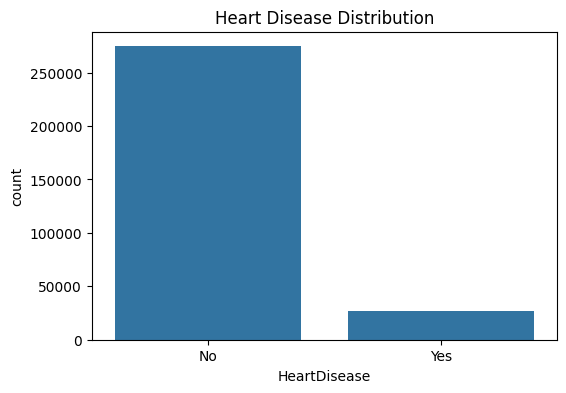

In [6]:
plt.figure(figsize=(6, 4))

sns.countplot(data=df, x="HeartDisease")

plt.title("Heart Disease Distribution")
plt.show()

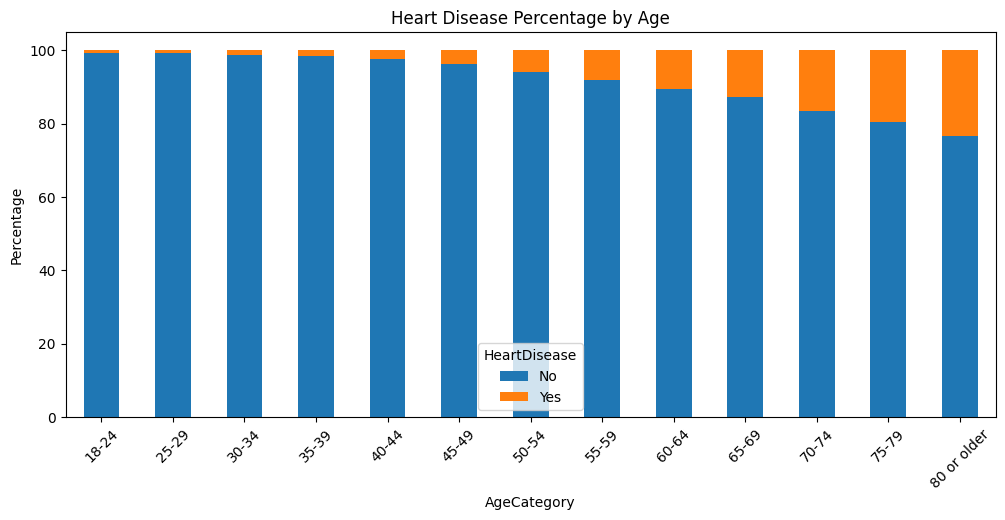

In [7]:
age_rate = pd.crosstab(
    df["AgeCategory"],
    df["HeartDisease"],
    normalize="index"
) * 100

age_rate.plot(kind="bar", stacked=True, figsize=(12, 5))

plt.title("Heart Disease Percentage by Age")
plt.ylabel("Percentage")
plt.xticks(rotation=45)
plt.show()

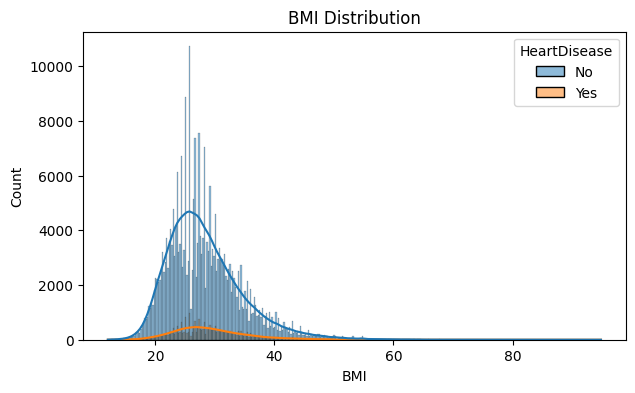

In [8]:
plt.figure(figsize=(7, 4))

sns.histplot(data=df, x="BMI", hue="HeartDisease", kde=True)

plt.title("BMI Distribution")
plt.show()

In [9]:
smoking_rate = pd.crosstab(
    df["Smoking"],
    df["HeartDisease"],
    normalize="index"
) * 100

print(smoking_rate)

HeartDisease         No        Yes
Smoking                           
No            93.526550   6.473450
Yes           87.459676  12.540324


In [10]:
X = df.drop("HeartDisease", axis=1)

y = df["HeartDisease"]

print("X Shape:", X.shape)
print("y Shape:", y.shape)

X Shape: (301717, 17)
y Shape: (301717,)


In [11]:
X_train_pool, X_test, y_train_pool, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

X_train, X_val, y_train, y_val = train_test_split(
    X_train_pool,
    y_train_pool,
    test_size=0.2,
    random_state=42,
    stratify=y_train_pool
)

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

Training: (193098, 17)
Validation: (48275, 17)
Testing: (60344, 17)


In [12]:
numerical_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Numerical Features:", numerical_features)

print("\nCategorical Features:", categorical_features)

Numerical Features: ['BMI', 'PhysicalHealth', 'MentalHealth', 'SleepTime']

Categorical Features: ['Smoking', 'AlcoholDrinking', 'Stroke', 'DiffWalking', 'Sex', 'AgeCategory', 'Race', 'Diabetic', 'PhysicalActivity', 'GenHealth', 'Asthma', 'KidneyDisease', 'SkinCancer']


In [13]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numerical_features),
    ("cat", categorical_pipeline, categorical_features)
])

In [14]:
X_train_processed = preprocessor.fit_transform(X_train)

X_val_processed = preprocessor.transform(X_val)

X_test_processed = preprocessor.transform(X_test)

print("Training Processed:", X_train_processed.shape)
print("Validation Processed:", X_val_processed.shape)
print("Testing Processed:", X_test_processed.shape)

Training Processed: (193098, 50)
Validation Processed: (48275, 50)
Testing Processed: (60344, 50)


In [15]:
lr_model = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=42
)

lr_model.fit(X_train_processed, y_train)

print("Logistic Regression Training Completed!")

Logistic Regression Training Completed!


In [21]:
y_val_prob = lr_model.predict_proba(X_val_processed)[:, 1]
print(y_val_prob)

[0.16025129 0.06624418 0.10194248 ... 0.74973015 0.17410604 0.32091376]


In [18]:
thresholds = [0.3, 0.4, 0.5, 0.6]

# Convert actual labels into 0 and 1
y_val_binary = (y_val == "Yes").astype(int)

results = []

for threshold in thresholds:

    y_val_pred = (y_val_prob >= threshold).astype(int)

    precision = precision_score(
        y_val_binary,
        y_val_pred,
        zero_division=0
    )

    recall = recall_score(
        y_val_binary,
        y_val_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_val_binary,
        y_val_pred,
        zero_division=0
    )

    results.append({
        "Threshold": threshold,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    })

results_df = pd.DataFrame(results)

print(results_df)

   Threshold  Precision    Recall  F1 Score
0        0.3   0.162877  0.919532  0.276735
1        0.4   0.193914  0.863365  0.316697
2        0.5   0.226119  0.781981  0.350800
3        0.6   0.264522  0.659789  0.377641


In [19]:
best_index = results_df["F1 Score"].idxmax()

best_threshold = results_df.loc[
    best_index, "Threshold"
]

print("Best Threshold:", best_threshold)

Best Threshold: 0.6


In [20]:
y_test_prob = lr_model.predict_proba(X_test_processed)[:, 1]

y_test_binary = (y_test == "Yes").astype(int)

y_test_pred = (
    y_test_prob >= best_threshold
).astype(int)

print(classification_report(
    y_test_binary,
    y_test_pred,
    target_names=["No", "Yes"]
))

              precision    recall  f1-score   support

          No       0.96      0.82      0.88     54892
         Yes       0.27      0.66      0.38      5452

    accuracy                           0.81     60344
   macro avg       0.61      0.74      0.63     60344
weighted avg       0.90      0.81      0.84     60344



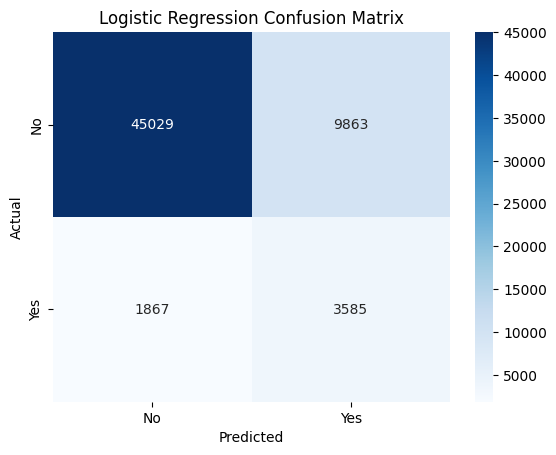

In [22]:
cm = confusion_matrix(
    y_test_binary,
    y_test_pred
)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No", "Yes"],
    yticklabels=["No", "Yes"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Logistic Regression Confusion Matrix")
plt.show()

In [23]:
accuracy = accuracy_score(y_test_binary, y_test_pred)

precision = precision_score(y_test_binary, y_test_pred)

recall = recall_score(y_test_binary, y_test_pred)

f1 = f1_score(y_test_binary, y_test_pred)

roc_auc = roc_auc_score(y_test_binary, y_test_prob)

pr_auc = average_precision_score(y_test_binary, y_test_prob)

print("Accuracy:", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("F1 Score:", round(f1, 4))
print("ROC-AUC:", round(roc_auc, 4))
print("PR-AUC:", round(pr_auc, 4))

Accuracy: 0.8056
Precision: 0.2666
Recall: 0.6576
F1 Score: 0.3794
ROC-AUC: 0.8319
PR-AUC: 0.3439


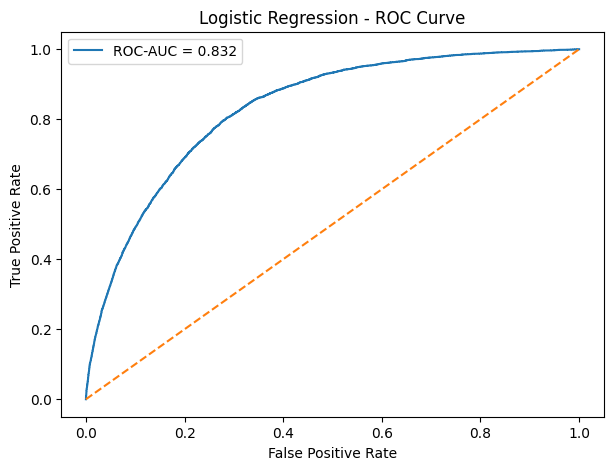

In [24]:
fpr, tpr, thresholds_roc = roc_curve(
    y_test_binary,
    y_test_prob
)

plt.figure(figsize=(7, 5))

plt.plot(fpr, tpr, label=f"ROC-AUC = {roc_auc:.3f}")

plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Logistic Regression - ROC Curve")

plt.legend()
plt.show()

In [25]:
import joblib

joblib.dump(lr_model, "logistic_regression_model.pkl")

joblib.dump(preprocessor, "heart_preprocessor.pkl")

joblib.dump(best_threshold, "best_threshold.pkl")

print("Model Saved Successfully!")

Model Saved Successfully!


In [26]:
loaded_model = joblib.load("logistic_regression_model.pkl")

loaded_preprocessor = joblib.load("heart_preprocessor.pkl")

loaded_threshold = joblib.load("best_threshold.pkl")

sample = X_test.iloc[[0]]

sample_processed = loaded_preprocessor.transform(sample)

probability = loaded_model.predict_proba(sample_processed)[0][1]

prediction = "Yes" if probability >= loaded_threshold else "No"

print("Probability:", round(probability, 4))
print("Predicted Status:", prediction)

Probability: 0.526
Predicted Status: No


In [27]:
!pip install fastapi uvicorn